# PS8: Fruit Object Detection using YOLOv8
Dataset: kaggle.com/datasets/afsananadia/fruits-images-dataset-object-detection
10 fruit classes. The original label files all use class 0; this notebook rewrites them with the true class extracted from the filename.

In [1]:
import torch

MIN_TOTAL_VRAM_GB = 6.0
MIN_FREE_VRAM_GB = 4.0


def _gpu_fail(reason, fix):
    bar = '=' * 66
    raise RuntimeError(f'\n{bar}\nGPU CHECK FAILED - training was NOT started.\n{bar}\nProblem : {reason}\nFix     : {fix}\n{bar}')


if not torch.cuda.is_available():
    _gpu_fail('No CUDA GPU is visible to PyTorch (CPU runtime).',
              'Colab: Runtime > Change runtime type > T4 GPU, then Run all.\n          Local: install NVIDIA driver + CUDA-enabled PyTorch.')

props = torch.cuda.get_device_properties(0)
total_gb = props.total_memory / 1024**3
free_gb = torch.cuda.mem_get_info(0)[0] / 1024**3

if total_gb + 0.5 < MIN_TOTAL_VRAM_GB:
    _gpu_fail(f'{props.name} has {total_gb:.1f} GB VRAM; this notebook needs >= {MIN_TOTAL_VRAM_GB:.0f} GB.',
              'Use a Colab T4 (15 GB). Smaller cards can only run reduced settings.')

if free_gb < MIN_FREE_VRAM_GB:
    _gpu_fail(f'Only {free_gb:.1f} GB of {total_gb:.1f} GB VRAM is free (need {MIN_FREE_VRAM_GB:.1f} GB).',
              'Runtime > Restart session, close other GPU notebooks, then Run all again.')

print(f'GPU OK - {props.name} | {total_gb:.1f} GB total | {free_gb:.1f} GB free')

GPU OK - Tesla T4 | 14.6 GB total | 14.5 GB free


In [2]:
%pip install -q ultralytics kagglehub

import re
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
from ultralytics import YOLO

SEED = 42
EPOCHS = 30
IMG = 640
WORKERS = 2
ALIASES = {'hogpulm': 'hogplum', 'lichi': 'litchi', 'hogplum': 'hogplum'}

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
try:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download('afsananadia/fruits-images-dataset-object-detection')
except Exception as exc:
    print('=' * 66)
    print('DATASET DOWNLOAD FAILED')
    print('Option 1: add a Kaggle API token (Colab Secrets: KAGGLE_API_TOKEN).')
    print('Option 2: set DATA_DIR manually to a local copy of the dataset.')
    print('=' * 66)
    raise SystemExit('Stopped: dataset not available.') from exc

SRC = Path(DATA_DIR)
OUT = Path('fruits_yolo')

for split in ['train', 'val']:
    (OUT / 'images' / split).mkdir(parents=True, exist_ok=True)
    (OUT / 'labels' / split).mkdir(parents=True, exist_ok=True)

def clean_name(stem):
    name = re.sub(r'^\d+_', '', stem).lower().replace(' ', '')
    return ALIASES.get(name, name)

all_classes = set()
for img_path in SRC.rglob('*.jpg'):
    all_classes.add(clean_name(img_path.stem))
classes = sorted(list(all_classes))
print('Classes:', classes)

split_map = {'train': 'Train File', 'val': 'Test File'}
counts = {'train': 0, 'val': 0}
for split, search_folder in split_map.items():
    folder_path = SRC / search_folder
    for img_path in folder_path.rglob('*.jpg'):
        txt_path = img_path.with_suffix('.txt')
        if not txt_path.exists():
            continue
        cls_name = clean_name(img_path.stem)
        if cls_name not in classes:
            continue
        cls_id = classes.index(cls_name)
        shutil.copy(img_path, OUT / 'images' / split / img_path.name)
        lines = txt_path.read_text().strip().split('\n')
        new_lines = []
        for line in lines:
            parts = line.split()
            if len(parts) >= 5:
                new_lines.append(f'{cls_id} {parts[1]} {parts[2]} {parts[3]} {parts[4]}')
        (OUT / 'labels' / split / f'{img_path.stem}.txt').write_text('\n'.join(new_lines))
        counts[split] += 1

yaml_content = f'path: {OUT.resolve().as_posix()}\ntrain: images/train\nval: images/val\nnames:\n'
yaml_content += '\n'.join(f'  {i}: {c}' for i, c in enumerate(classes))
(OUT / 'data.yaml').write_text(yaml_content)
print(f'Dataset ready: {counts["train"]} train, {counts["val"]} val images.')
print('data.yaml written to:', OUT / 'data.yaml')

100%|██████████| 70.2M/70.2M [00:05<00:00, 13.6MB/s]

Extracting files...


Classes: ['apple', 'banana', 'grapes', 'guava', 'hogplum', 'jackfruit', 'litchi', 'mango', 'orange', 'papaya']
Dataset ready: 280 train, 77 val images.
data.yaml written to: fruits_yolo/data.yaml


## Training

In [4]:
model = YOLO('yolov8n.pt')
model.train(data=str((OUT / 'data.yaml').resolve()), epochs=EPOCHS, imgsz=IMG,
            batch=-1, workers=WORKERS, seed=SEED, patience=15,
            project='runs', name='fruit_det', exist_ok=True)
save_dir = Path(model.trainer.save_dir)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fruits_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fruit_det, nbs=64, nms=None, opset=None, optimize=False, op

## Evaluation

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2966.8±1665.7 MB/s, size: 1135.2 KB)
val: Scanning /content/fruits_yolo/labels/val.cache... 77 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 77/77 23.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.7s/it 8.5s
                   all         77         77      0.423      0.312      0.278      0.189
                 apple          8          8          1       0.35      0.454      0.361
                banana          5          5          1          0          0          0
                grapes          8          8      0.401      0.625      0.457      0.272
                 guava          8          8      0.333      0.375      0.271      0.226
               hogplum          8          8    

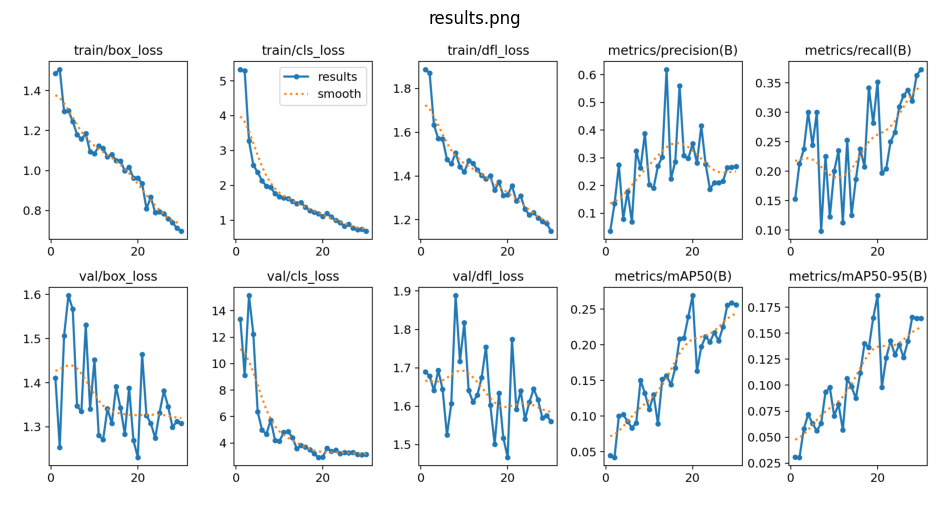

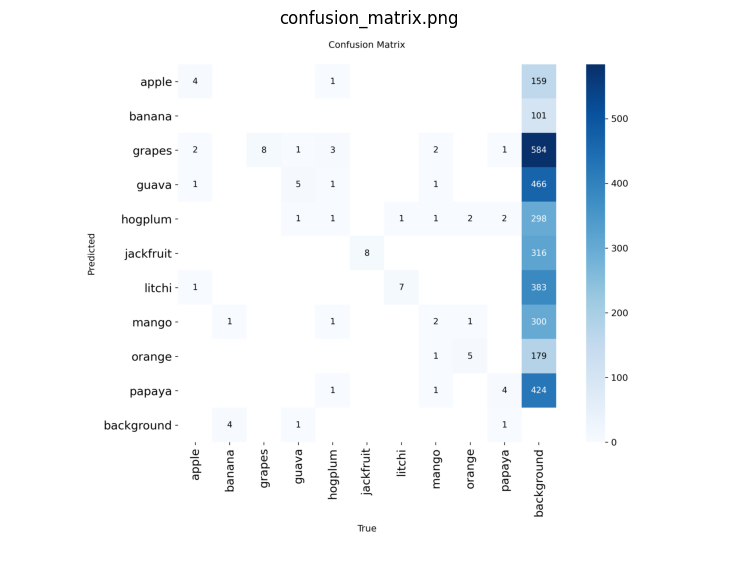

In [5]:
metrics = model.val(data=str((OUT / 'data.yaml').resolve()))
print(f'Precision: {metrics.box.mp:.4f}   Recall: {metrics.box.mr:.4f}')
print(f'mAP@0.5: {metrics.box.map50:.4f}   mAP@0.5:0.95: {metrics.box.map:.4f}')

for name in ['results.png', 'confusion_matrix.png']:
    p = save_dir / name
    if p.exists():
        plt.figure(figsize=(12, 7))
        plt.imshow(plt.imread(str(p)))
        plt.title(name)
        plt.axis('off')
        plt.show()

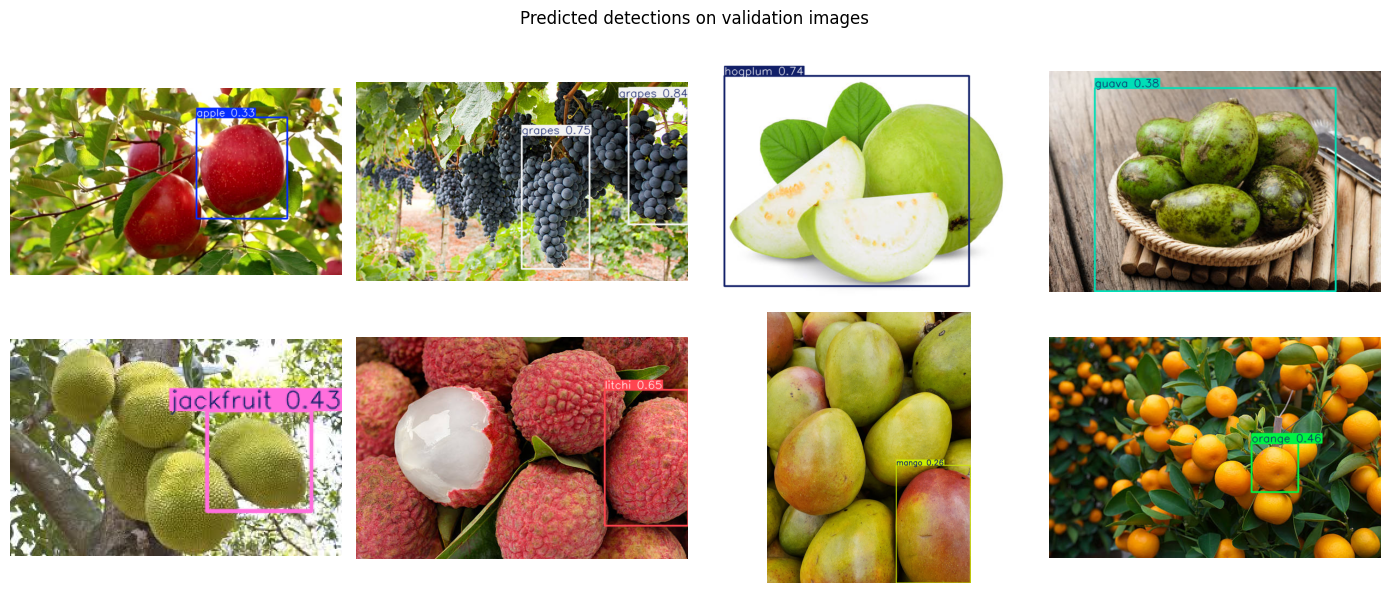

In [6]:
val_imgs = sorted((OUT / 'images' / 'val').glob('*.jpg'))
samples = val_imgs[:8] if len(val_imgs) >= 8 else val_imgs
results = model.predict([str(p) for p in samples], imgsz=IMG, conf=0.25, verbose=False)
plt.figure(figsize=(14, 6))
for i, r in enumerate(results):
    plt.subplot(2, 4, i + 1)
    plt.imshow(r.plot()[..., ::-1])
    plt.axis('off')
plt.suptitle('Predicted detections on validation images')
plt.tight_layout()
plt.show()

## Save and single-image inference

In [7]:
out_dir = Path('outputs')
out_dir.mkdir(exist_ok=True)
shutil.copy2(save_dir / 'weights' / 'best.pt', out_dir / 'fruits_yolov8n_det.pt')
print('Saved:', out_dir / 'fruits_yolov8n_det.pt')


def detect_image(path, conf=0.25):
    r = model.predict(str(path), imgsz=IMG, conf=conf, verbose=False)[0]
    plt.figure(figsize=(6, 6))
    plt.imshow(r.plot()[..., ::-1])
    plt.axis('off')
    plt.show()
    return [(r.names[int(b.cls)], round(float(b.conf), 3), tuple(b.xyxy[0].tolist())) for b in r.boxes]

Saved: outputs/fruits_yolov8n_det.pt
